In [2]:
# Credit Card Default Prediction Project

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All libraries imported successfully!")
print("Credit Card Default Prediction Project Started")

All libraries imported successfully!
Credit Card Default Prediction Project Started


In [3]:
# Step 1: Download the dataset

from ucimlrepo import fetch_ucirepo

# Fetch Credit Card Default dataset from UCI
credit_card = fetch_ucirepo(id=350)

# Separate input features and target
X = credit_card.data.features
y = credit_card.data.targets

# Display dataset information
print("Dataset downloaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display first five rows
display(X.head())

Dataset downloaded successfully!
Features shape: (30000, 23)
Target shape: (30000, 1)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [4]:
# Step 2: Understand the dataset

print("Feature column names:")
print(X.columns.tolist())

print("\nTarget column name:")
print(y.columns.tolist())

print("\nFirst five target values:")
display(y.head())

print("\nTarget value distribution:")
print(y.iloc[:, 0].value_counts())

Feature column names:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Target column name:
['Y']

First five target values:


,Y
0,1
1,1
2,0
3,0
4,0



Target value distribution:
Y
0    23364
1     6636
Name: count, dtype: int64


In [5]:
# Step 3: View feature descriptions

display(credit_card.variables[
    ['name', 'role', 'description']
])

,name,role,description
0,ID,ID,None
1,X1,Feature,LIMIT_BAL
2,X2,Feature,SEX
3,X3,Feature,EDUCATION
4,X4,Feature,MARRIAGE
5,X5,Feature,AGE
6,X6,Feature,PAY_0
7,X7,Feature,PAY_2
8,X8,Feature,PAY_3
9,X9,Feature,PAY_4


In [6]:
# Step 4: Rename columns for better understanding

column_names = [
    'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE',
    'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6',
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

# Rename feature columns
X.columns = column_names

# Rename target column
y.columns = ['DEFAULT']

# Combine features and target
df = pd.concat([X, y], axis=1)

# Display updated dataset
display(df.head())

print("Dataset shape:", df.shape)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Dataset shape: (30000, 24)


In [7]:
# Step 5: Check missing values and duplicates

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nTotal duplicate records:")
print(df.duplicated().sum())

print("\nDataset information:")
df.info()

Missing values in each column:
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

Total missing values:
0

Total duplicate records:
35

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_0      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null 

In [8]:
# Step 6: Remove duplicate records

print("Rows before cleaning:", len(df))

# Remove exact duplicate rows
df = df.drop_duplicates()

# Reset row numbering
df = df.reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Duplicates remaining:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Rows before cleaning: 30000
Rows after cleaning: 29965
Duplicates remaining: 0
Final dataset shape: (29965, 24)


Customer Default Distribution:
DEFAULT
0    23335
1     6630
Name: count, dtype: int64


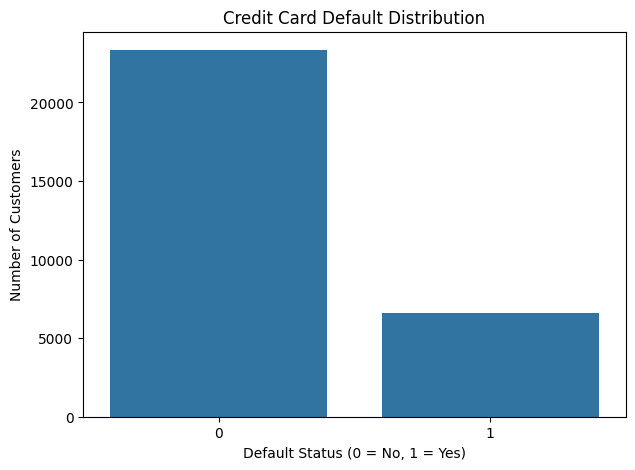

In [9]:
# Step 7: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each category
print("Customer Default Distribution:")
print(df['DEFAULT'].value_counts())

# Create count plot
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='DEFAULT')

plt.title('Credit Card Default Distribution')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

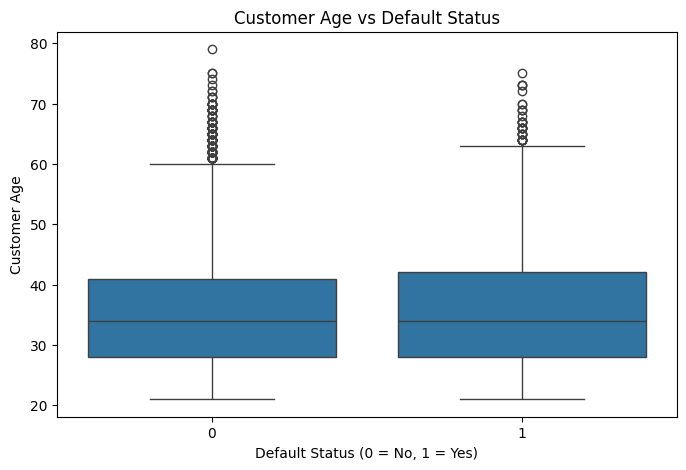

In [10]:
# Step 8: Analyze age and default

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='DEFAULT', y='AGE')

plt.title('Customer Age vs Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Customer Age')

plt.show()

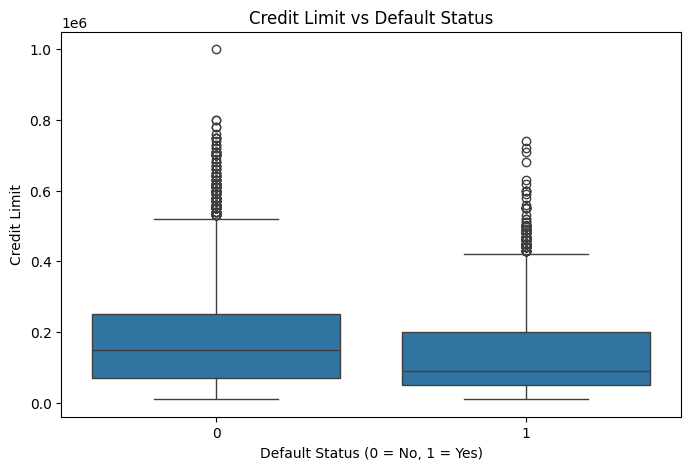

In [11]:
# Step 9: Analyze credit limit and default

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='DEFAULT', y='LIMIT_BAL')

plt.title('Credit Limit vs Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Credit Limit')

plt.show()

Repayment Status Distribution:
PAY_0
-2     2750
-1     5682
 0    14737
 1     3667
 2     2666
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

Default Rate by Repayment Status:
PAY_0
-2    13.236364
-1    16.789863
 0    12.811291
 1    34.033270
 2    69.129782
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: DEFAULT, dtype: float64


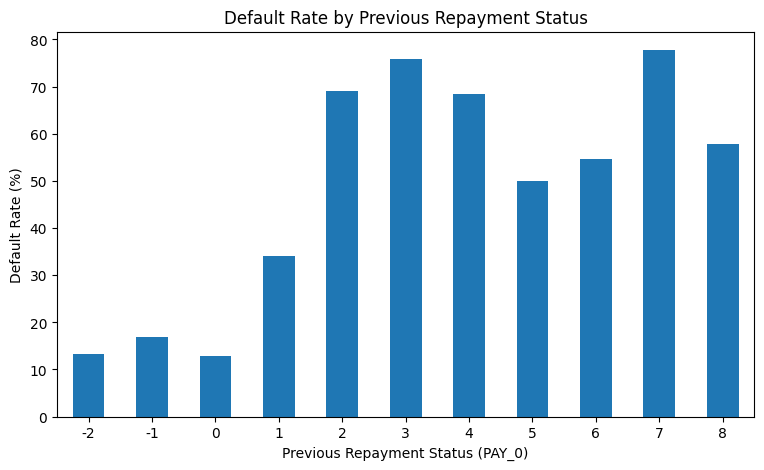

In [12]:
# Step 10: Analyze repayment status and default

print("Repayment Status Distribution:")
print(df['PAY_0'].value_counts().sort_index())

# Calculate default percentage for each repayment status
default_rate = df.groupby('PAY_0')['DEFAULT'].mean() * 100

print("\nDefault Rate by Repayment Status:")
print(default_rate)

# Create graph
plt.figure(figsize=(9, 5))

default_rate.plot(kind='bar')

plt.title('Default Rate by Previous Repayment Status')
plt.xlabel('Previous Repayment Status (PAY_0)')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

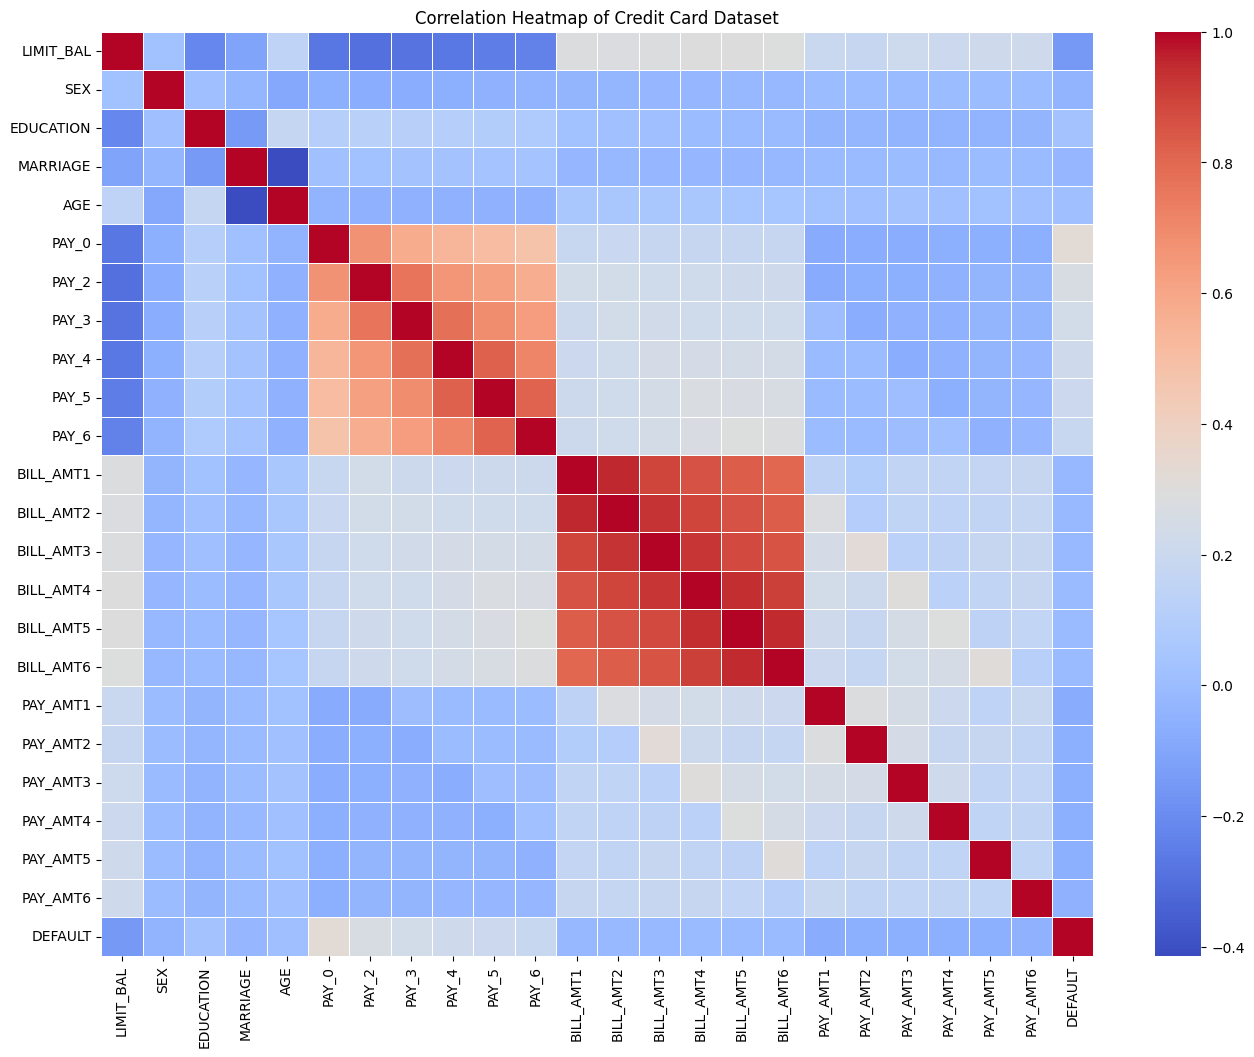

In [13]:
# Step 11: Correlation heatmap

plt.figure(figsize=(16, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Credit Card Dataset')

plt.show()

Correlation of Features with Default:
PAY_0        0.324964
PAY_2        0.263656
PAY_3        0.235230
PAY_4        0.216551
PAY_5        0.204059
PAY_6        0.186740
EDUCATION    0.028017
AGE          0.013619
BILL_AMT6   -0.005469
BILL_AMT5   -0.006859
BILL_AMT4   -0.010259
BILL_AMT3   -0.014182
BILL_AMT2   -0.014302
BILL_AMT1   -0.019758
MARRIAGE    -0.024019
SEX         -0.039742
PAY_AMT6    -0.053250
PAY_AMT5    -0.055194
PAY_AMT3    -0.056319
PAY_AMT4    -0.056898
PAY_AMT2    -0.058643
PAY_AMT1    -0.073015
LIMIT_BAL   -0.153871
Name: DEFAULT, dtype: float64


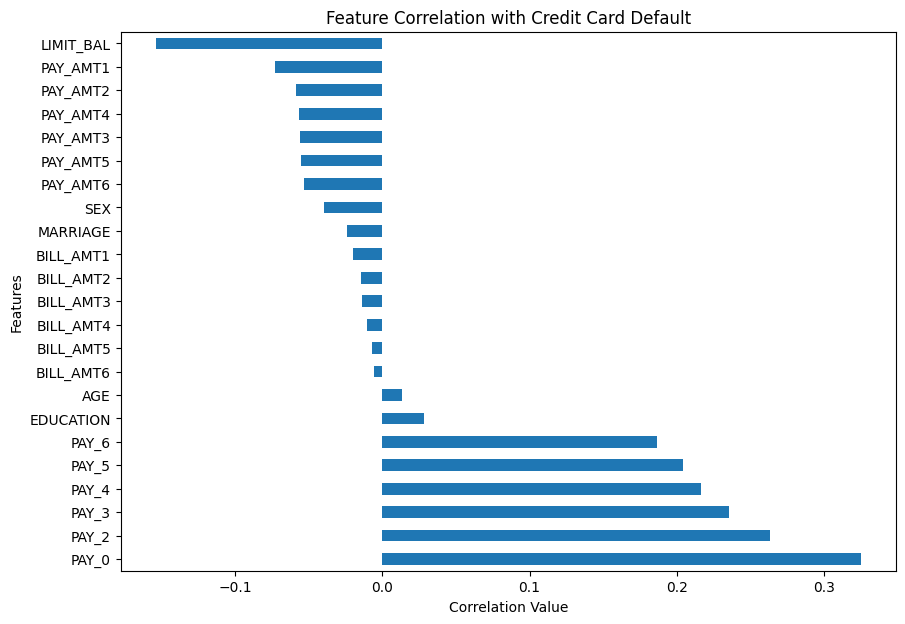

In [14]:
# Step 12: Correlation of all features with default

default_correlation = df.corr()['DEFAULT'].drop('DEFAULT')

default_correlation = default_correlation.sort_values(
    ascending=False
)

print("Correlation of Features with Default:")
print(default_correlation)

# Plot correlation
plt.figure(figsize=(10, 7))

default_correlation.plot(kind='barh')

plt.title('Feature Correlation with Credit Card Default')
plt.xlabel('Correlation Value')
plt.ylabel('Features')

plt.show()

In [15]:
# Step 13: Split data into training and testing sets

from sklearn.model_selection import train_test_split

# Separate input features and target
X_ml = df.drop('DEFAULT', axis=1)
y_ml = df['DEFAULT']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_ml,
    y_ml,
    test_size=0.20,
    random_state=42,
    stratify=y_ml
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Default Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Default Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (23972, 23)
Testing Features: (5993, 23)
Training Target: (23972,)
Testing Target: (5993,)

Training Default Distribution:
DEFAULT
0    77.874187
1    22.125813
Name: proportion, dtype: float64

Testing Default Distribution:
DEFAULT
0    77.874187
1    22.125813
Name: proportion, dtype: float64


In [16]:
# Step 14: Train Logistic Regression Model

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model trained successfully!")


Logistic Regression Model trained successfully!


LOGISTIC REGRESSION MODEL RESULTS
----------------------------------
Accuracy: 0.6864675454697147
Precision: 0.37561853351327035
Recall: 0.6297134238310709
F1 Score: 0.4705550859397013
ROC-AUC: 0.7161577986834167

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.70      0.78      4667
           1       0.38      0.63      0.47      1326

    accuracy                           0.69      5993
   macro avg       0.62      0.67      0.62      5993
weighted avg       0.76      0.69      0.71      5993



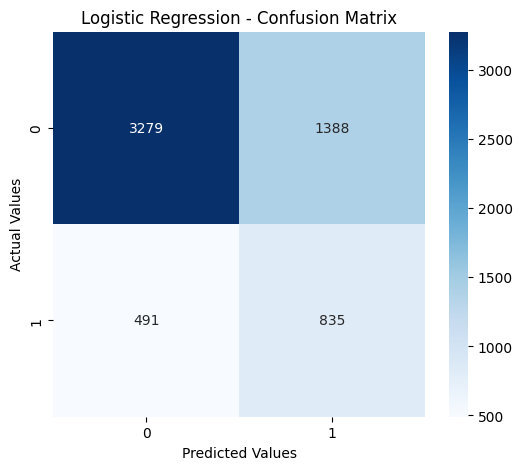

In [17]:
# Step 15: Evaluate Logistic Regression Model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict using testing data
y_pred = logistic_model.predict(X_test)

# Predict probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
print("LOGISTIC REGRESSION MODEL RESULTS")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [18]:
# Step 16: Train Decision Tree Model

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    max_depth=6,
    class_weight='balanced',
    random_state=42
)

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")

Decision Tree Model trained successfully!


DECISION TREE MODEL RESULTS
----------------------------------
Accuracy: 0.7759052227598865
Precision: 0.4942528735632184
Recall: 0.5512820512820513
F1 Score: 0.5212121212121212
ROC-AUC: 0.7520288628381748

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.84      0.85      4667
           1       0.49      0.55      0.52      1326

    accuracy                           0.78      5993
   macro avg       0.68      0.70      0.69      5993
weighted avg       0.79      0.78      0.78      5993



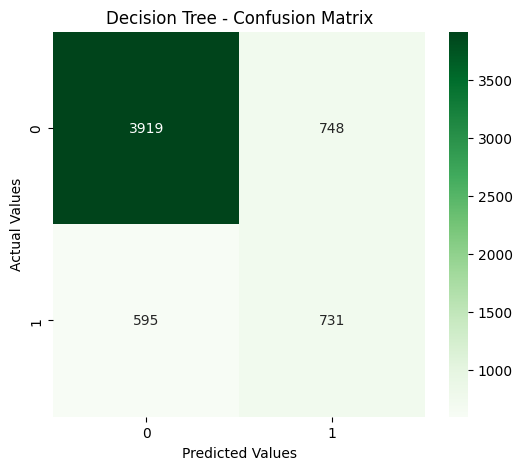

In [19]:
# Step 17: Evaluate Decision Tree Model

# Predict test data
dt_pred = decision_tree.predict(X_test)

# Predict probabilities
dt_prob = decision_tree.predict_proba(X_test)[:, 1]

# Calculate performance metrics
print("DECISION TREE MODEL RESULTS")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

# Confusion matrix
cm_dt = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens')

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

In [20]:
# Step 18: Train Random Forest Model

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest.fit(X_train, y_train)

print("Random Forest Model trained successfully!")

Random Forest Model trained successfully!


RANDOM FOREST MODEL RESULTS
----------------------------------
Accuracy: 0.7917570498915402
Precision: 0.5300462249614792
Recall: 0.5188536953242836
F1 Score: 0.524390243902439
ROC-AUC: 0.7659329278677898

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.87      0.87      4667
           1       0.53      0.52      0.52      1326

    accuracy                           0.79      5993
   macro avg       0.70      0.69      0.70      5993
weighted avg       0.79      0.79      0.79      5993



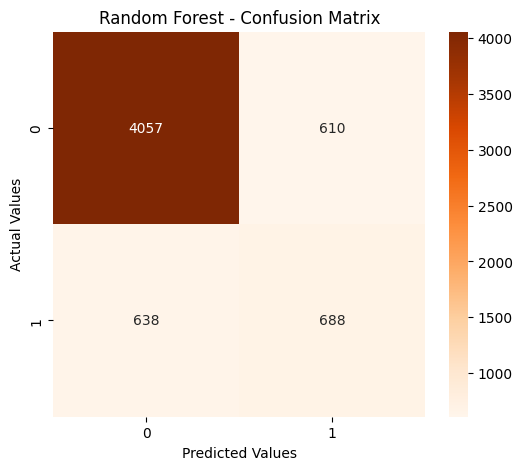

In [21]:
# Step 19: Evaluate Random Forest Model

# Predict test data
rf_pred = random_forest.predict(X_test)

# Predict probabilities
rf_prob = random_forest.predict_proba(X_test)[:, 1]

# Calculate performance metrics
print("RANDOM FOREST MODEL RESULTS")
print("----------------------------------")

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

# Confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges')

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6865,0.3756,0.6297,0.4706,0.7162
1,Decision Tree,0.7759,0.4943,0.5513,0.5212,0.7520
2,Random Forest,0.7918,0.5300,0.5189,0.5244,0.7659


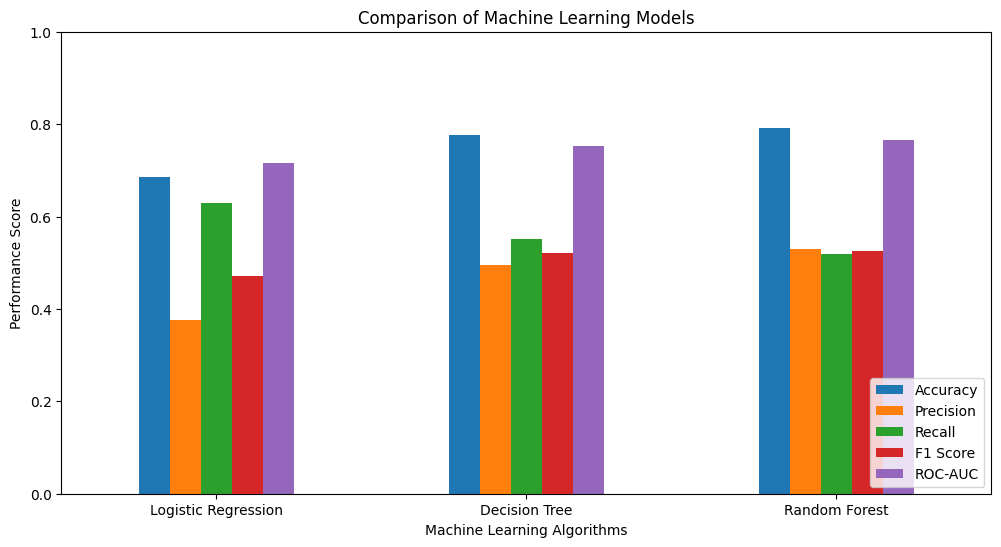

In [22]:
# Step 20: Compare all three models

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    'Precision': [
        precision_score(y_test, y_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred)
    ],
    'Recall': [
        recall_score(y_test, y_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, dt_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

display(results.round(4))

# Plot comparison
results.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparison of Machine Learning Models')
plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Algorithms')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()

Top 10 Important Features:


,Feature,Importance
5,PAY_0,0.197855
6,PAY_2,0.092787
0,LIMIT_BAL,0.050999
17,PAY_AMT1,0.046628
11,BILL_AMT1,0.046141
18,PAY_AMT2,0.044989
7,PAY_3,0.041460
8,PAY_4,0.041121
12,BILL_AMT2,0.039417
19,PAY_AMT3,0.039118


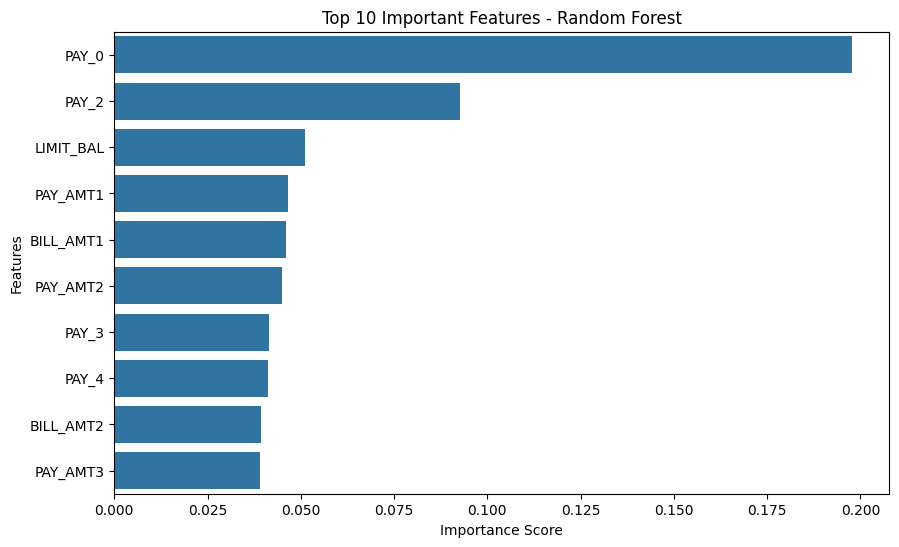

In [23]:
# Step 21: Feature Importance using Random Forest

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': random_forest.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.show()

In [24]:
# Step 22: Experiment with prediction thresholds

from sklearn.metrics import precision_score, recall_score, f1_score

# Random Forest probabilities
rf_prob = random_forest.predict_proba(X_test)[:, 1]

# Test two thresholds
for threshold in [0.50, 0.40, 0.35]:

    predictions = (rf_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1 Score:", f1_score(y_test, predictions))


Threshold: 0.5
Precision: 0.5300462249614792
Recall: 0.5188536953242836
F1 Score: 0.524390243902439

Threshold: 0.4
Precision: 0.4332298136645963
Recall: 0.6312217194570136
F1 Score: 0.5138121546961326

Threshold: 0.35
Precision: 0.37181996086105673
Recall: 0.7164404223227753
F1 Score: 0.48956454522030407


In [29]:

# Step 23: 5-Fold Cross-Validation and Hyperparameter Tuning

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Create a reproducible machine learning pipeline
rf_pipeline = Pipeline([
    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Parameters to test
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [10, 15],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

# Set up 5-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform grid search using training data only
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=1,
    verbose=1
)

print("Starting 5-Fold Cross-Validation and Grid Search...")

grid_search.fit(X_train, y_train)

# Display the best results
print("\nTUNING COMPLETED")
print("------------------------------")
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest 5-Fold Cross-Validation ROC-AUC:")
print(round(grid_search.best_score_, 4))

# Store the best pipeline
best_pipeline = grid_search.best_estimator_

print("\nBest pipeline created successfully!")


Starting 5-Fold Cross-Validation and Grid Search...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

TUNING COMPLETED
------------------------------
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best 5-Fold Cross-Validation ROC-AUC:
0.7801

Best pipeline created successfully!


TUNED RANDOM FOREST MODEL RESULTS
----------------------------------
5-Fold CV ROC-AUC: 0.7801
Test Accuracy: 0.7809
Test Precision: 0.5045
Test Recall: 0.5551
Test F1 Score: 0.5285
Test ROC-AUC: 0.7679

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4667
           1       0.50      0.56      0.53      1326

    accuracy                           0.78      5993
   macro avg       0.69      0.70      0.69      5993
weighted avg       0.79      0.78      0.78      5993



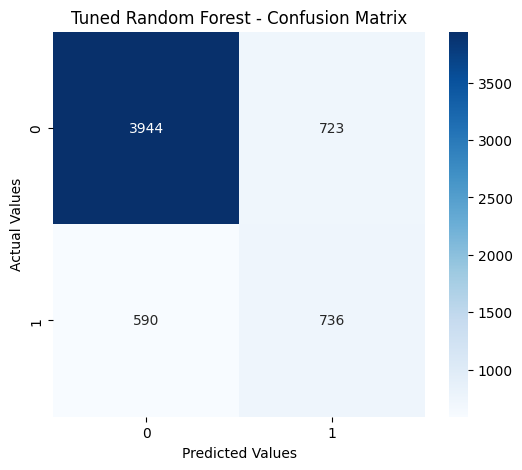

In [30]:

# Step 24: Evaluate the Tuned Random Forest Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict using the best tuned pipeline
tuned_predictions = best_pipeline.predict(X_test)

# Calculate default probabilities
tuned_probabilities = best_pipeline.predict_proba(X_test)[:, 1]

# Display evaluation metrics
print("TUNED RANDOM FOREST MODEL RESULTS")
print("----------------------------------")

print("5-Fold CV ROC-AUC:", round(grid_search.best_score_, 4))
print("Test Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Test Precision:", round(precision_score(y_test, tuned_predictions), 4))
print("Test Recall:", round(recall_score(y_test, tuned_predictions), 4))
print("Test F1 Score:", round(f1_score(y_test, tuned_predictions), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, tuned_probabilities), 4))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

# Confusion matrix
cm_tuned = confusion_matrix(y_test, tuned_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues')

plt.title('Tuned Random Forest - Confusion Matrix')
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')

plt.show()


In [31]:

# Step 25: Save the Final Tuned Pipeline

import joblib

# Save the complete tuned pipeline
joblib.dump(
    best_pipeline,
    'credit_card_default_model.pkl'
)

print("Final tuned pipeline saved successfully!")

# Load the saved pipeline to verify it
loaded_model = joblib.load('credit_card_default_model.pkl')

print("Saved model loaded successfully!")
print("Model type:", type(loaded_model))


Final tuned pipeline saved successfully!
Saved model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


In [33]:

# Step 26: Verify the Saved Tuned Model

import joblib
import os

# Check the saved model file
print("Current Notebook Folder:", os.getcwd())
print("Model File Exists:", os.path.exists("credit_card_default_model.pkl"))
print("Model File Size:", round(
    os.path.getsize("credit_card_default_model.pkl") / (1024 * 1024), 2
), "MB")

# Load the saved pipeline
loaded_model = joblib.load("credit_card_default_model.pkl")

# Test prediction on one customer
sample_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_customer)
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("\nSAVED MODEL PREDICTION")
print("----------------------")
print("Predicted Default:", prediction[0])
print("Default Probability:", round(probability * 100, 2), "%")
print("Actual Result:", y_test.iloc[0])


Current Notebook Folder: C:\Users\bhola\Credit_Card_Default_Prediction
Model File Exists: True
Model File Size: 11.17 MB

SAVED MODEL PREDICTION
----------------------
Predicted Default: 0
Default Probability: 35.67 %
Actual Result: 0


In [26]:
# Step 24: Load saved model and make a prediction

import joblib

# Load the saved model
loaded_model = joblib.load('credit_card_default_model.pkl')

# Select one customer from testing data
sample_customer = X_test.iloc[[0]]

# Predict default
prediction = loaded_model.predict(sample_customer)

# Calculate default probability
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("CUSTOMER DEFAULT PREDICTION")
print("---------------------------")

if prediction[0] == 1:
    print("Prediction: Customer may DEFAULT")
else:
    print("Prediction: Customer may NOT DEFAULT")

print("Default Probability:", round(probability * 100, 2), "%")

print("Actual Result:", y_test.iloc[0])

CUSTOMER DEFAULT PREDICTION
---------------------------
Prediction: Customer may NOT DEFAULT
Default Probability: 31.08 %
Actual Result: 0


In [27]:
# Step 25: Test model on 10 customers

sample_data = X_test.iloc[:10]

# Make predictions
sample_predictions = loaded_model.predict(sample_data)

# Get probabilities
sample_probabilities = loaded_model.predict_proba(sample_data)[:, 1]

# Create result table
prediction_results = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': sample_predictions,
    'Default Probability (%)': (
        sample_probabilities * 100
    ).round(2)
})

# Check whether prediction is correct
prediction_results['Result'] = (
    prediction_results['Actual'] ==
    prediction_results['Predicted']
).map({True: 'Correct', False: 'Incorrect'})

display(prediction_results)

print(
    "\nCorrect predictions:",
    (prediction_results['Actual'] ==
     prediction_results['Predicted']).sum(),
    "out of 10"
)

,Actual,Predicted,Default Probability (%),Result
0,0,0,31.08,Correct
1,0,0,20.97,Correct
2,0,0,32.37,Correct
3,0,0,34.71,Correct
4,0,0,9.22,Correct
5,0,0,19.01,Correct
6,0,0,30.65,Correct
7,0,0,28.06,Correct
8,1,0,21.37,Incorrect
9,0,0,19.31,Correct



Correct predictions: 9 out of 10


In [28]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.Collecting streamlit
     ---------------------------------------- 10.3/10.3 MB 1.8 MB/s eta 0:00:00
     ---------------------------------------- 27.8/27.8 MB 1.3 MB/s eta 0:00:00
     ---------------------------------------- 79.1/79.1 kB 4.3 MB/s eta 0:00:00
     -------------------------------------- 797.6/797.6 kB 1.1 MB/s eta 0:00:00
     -------------------------------------- 92.6/92.6 kB 876.6 kB/s eta 0:00:00
     ------------------------------------ 456.5/456.5 kB 549.6 kB/s eta 0:00:00
     ---------------------------------------- 11.4/11.4 MB 1.9 MB/s eta 0:00:00
     ---------------------------------------- 87.4/87.4 kB 1.6 MB/s eta 0:00:00
     ---------------------------------------- 79.0/79.0 kB 2.2 MB/s eta 0:00:00
     -------------------------------------- 180.2/180.2 kB 2.7 MB/s eta 0:00:00
     -------------------------------------- 490.6/490.6 kB 3.1 MB/s eta 0:00:00




[notice] A new release of pip available: 22.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
